Maël Conejos Crusson - B00175970

# Fundamentals of AI & Data Science Project

## Imports, Loading Dataset, Setting Classification Target

In [3]:
# Imports
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.utils import resample
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, OrdinalEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings('ignore')

In [ ]:
# Loading Dataset
df = pd.read_csv('Dataset1.csv')

In [5]:
# Classification Target
df['attack'] = (df['is_attack'] == 'Attack').astype(int)

## EDA

In [6]:
# Dataframe Shape
df.shape

(6000, 20)

In [7]:
# Dataframe Info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   session_id        6000 non-null   object 
 1   protocol          5580 non-null   object 
 2   device_type       6000 non-null   object 
 3   vpn_status        6000 non-null   object 
 4   region            6000 non-null   object 
 5   login_attempts    6000 non-null   int64  
 6   failed_logins     6000 non-null   int64  
 7   bytes_sent        6000 non-null   float64
 8   bytes_received    5580 non-null   float64
 9   packet_rate       6000 non-null   float64
 10  connection_count  6000 non-null   int64  
 11  tcp_flags         6000 non-null   object 
 12  port_number       6000 non-null   int64  
 13  session_retries   6000 non-null   int64  
 14  signal_strength   5580 non-null   float64
 15  privilege_level   6000 non-null   object 
 16  anomaly_score     6000 non-null   float64


attack
0    4481
1    1519
Name: count, dtype: int64
attack
0    74.683333
1    25.316667
Name: proportion, dtype: float64



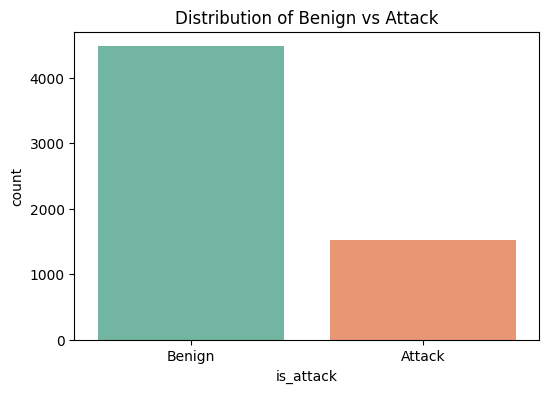

In [8]:
# Target Distribution
print(df['attack'].value_counts())
print(df['attack'].value_counts(normalize=True) * 100)
print("")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='is_attack', palette='Set2')
plt.title('Distribution of Benign vs Attack')
plt.show()

In [9]:
# Numeric Columns Analysis #1
print(df.describe())

       login_attempts  failed_logins    bytes_sent  bytes_received  \
count     6000.000000    6000.000000   6000.000000     5580.000000   
mean         1.972500       1.020667   5275.753584     5981.881281   
std          1.415537       1.004527   3132.622483     1994.673822   
min          0.000000       0.000000    100.000000      100.000000   
25%          1.000000       0.000000   4009.308961     4662.928544   
50%          2.000000       1.000000   5013.713497     5992.395457   
75%          3.000000       2.000000   6060.269321     7333.109710   
max          9.000000       7.000000  48743.941649    13019.206996   

       packet_rate  connection_count  port_number  session_retries  \
count  6000.000000       6000.000000  6000.000000       6000.00000   
mean    126.137459          4.963500   472.757000          1.01950   
std      71.772746          2.268485  1033.630588          1.00081   
min      23.362556          0.000000    21.000000          0.00000   
25%      99.854757 

In [10]:
# Numeric Columns Analysis #2
for col in df.select_dtypes(include='number').columns:
  print(df[col].value_counts())
  print(f"Unique values: {df[col].nunique()}")
  print("")

login_attempts
1    1632
2    1632
3    1053
0     851
4     514
5     217
6      74
7      22
8       4
9       1
Name: count, dtype: int64
Unique values: 10

failed_logins
1    2267
0    2127
2    1115
3     369
4      96
5      22
7       2
6       2
Name: count, dtype: int64
Unique values: 8

bytes_sent
4612.202137    1
7332.054264    1
4607.750299    1
6456.224802    1
3823.556471    1
              ..
5798.763455    1
7234.103007    1
5681.503452    1
4200.249009    1
3688.587042    1
Name: count, Length: 6000, dtype: int64
Unique values: 6000

bytes_received
100.000000     12
3617.792789     1
9850.436696     1
7525.647668     1
5790.192570     1
               ..
4583.471733     1
9234.385904     1
7249.004321     1
4843.432132     1
4128.198755     1
Name: count, Length: 5569, dtype: int64
Unique values: 5569

packet_rate
104.738663    1
112.613969    1
117.701455    1
132.032680    1
135.448494    1
             ..
116.326988    1
106.159532    1
206.334163    1
127.567880   

In [11]:
# Categorical Columns Analysis
for col in df.select_dtypes(include='object').columns:
  print(df[col].value_counts())
  print(f"Unique values: {df[col].nunique()}")
  print("")

session_id
S005983    1
S005982    1
S005981    1
S005980    1
S005979    1
          ..
S000004    1
S000003    1
S000002    1
S000001    1
S000000    1
Name: count, Length: 6000, dtype: int64
Unique values: 6000

protocol
TCP     2532
UDP     1378
tcp      572
Udp      557
ICMP     541
Name: count, dtype: int64
Unique values: 5

device_type
Server         1562
IoT            1510
Workstation    1470
Mobile         1458
Name: count, dtype: int64
Unique values: 4

vpn_status
Off    4184
On     1816
Name: count, dtype: int64
Unique values: 2

region
APAC    1519
US      1500
EU      1492
ME      1489
Name: count, dtype: int64
Unique values: 4

tcp_flags
FIN        1552
SYN-ACK    1531
ACK        1459
SYN        1458
Name: count, dtype: int64
Unique values: 4

privilege_level
user     4247
admin    1141
guest     612
Name: count, dtype: int64
Unique values: 3

is_attack
Benign    4481
Attack    1519
Name: count, dtype: int64
Unique values: 2



In [12]:
# Missing Values
missing = pd.DataFrame({
 'Missing Count': df.isnull().sum(),
 'Missing %': (df.isnull().sum() / len(df)) * 100
})
missing = missing[missing['Missing Count'] > 0].sort_values('Missing %', ascending=False)
print(missing)

                 Missing Count  Missing %
protocol                   420        7.0
bytes_received             420        7.0
signal_strength            420        7.0


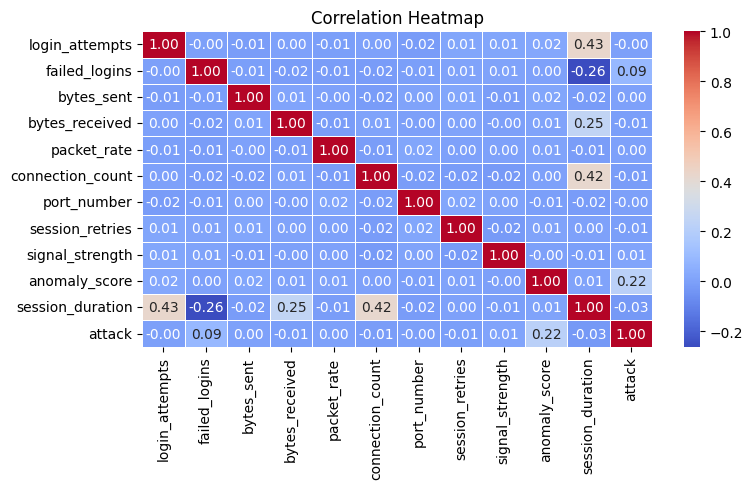

In [13]:
# Correlation Heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f',
linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

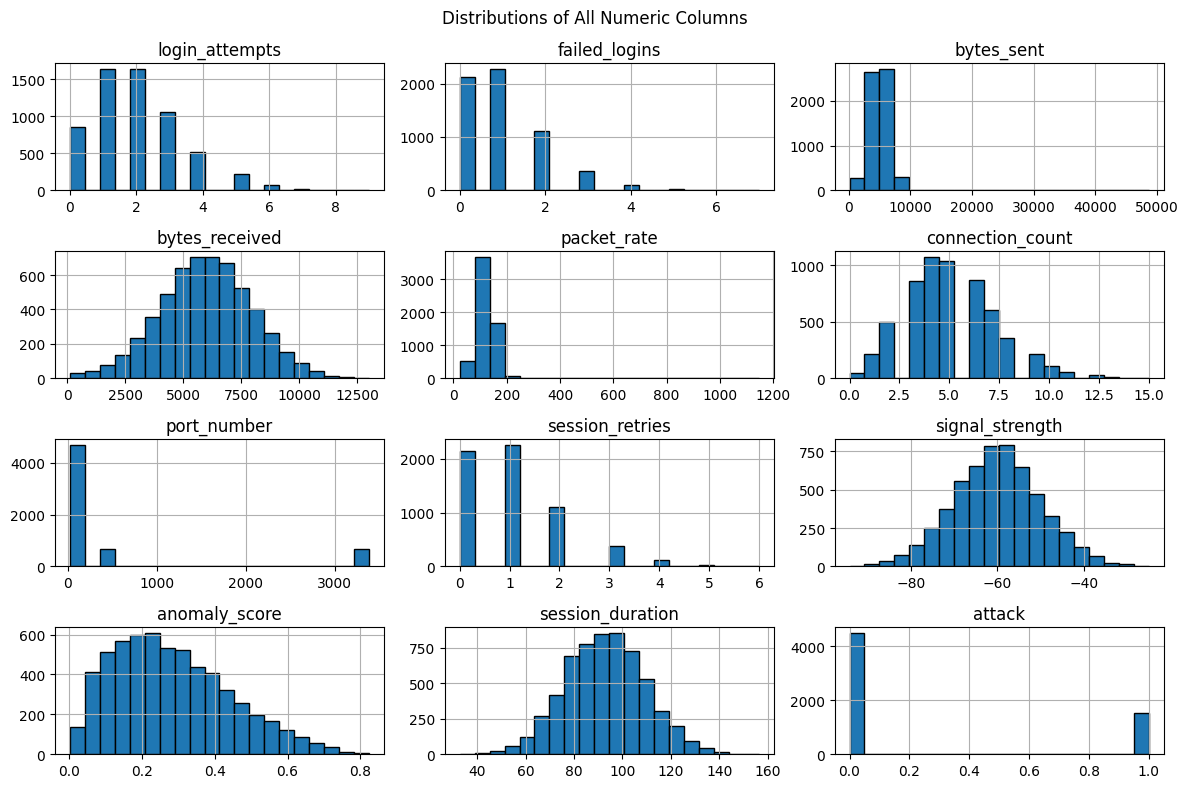

In [14]:
# Histograms
df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle('Distributions of All Numeric Columns')
plt.tight_layout()
plt.show()

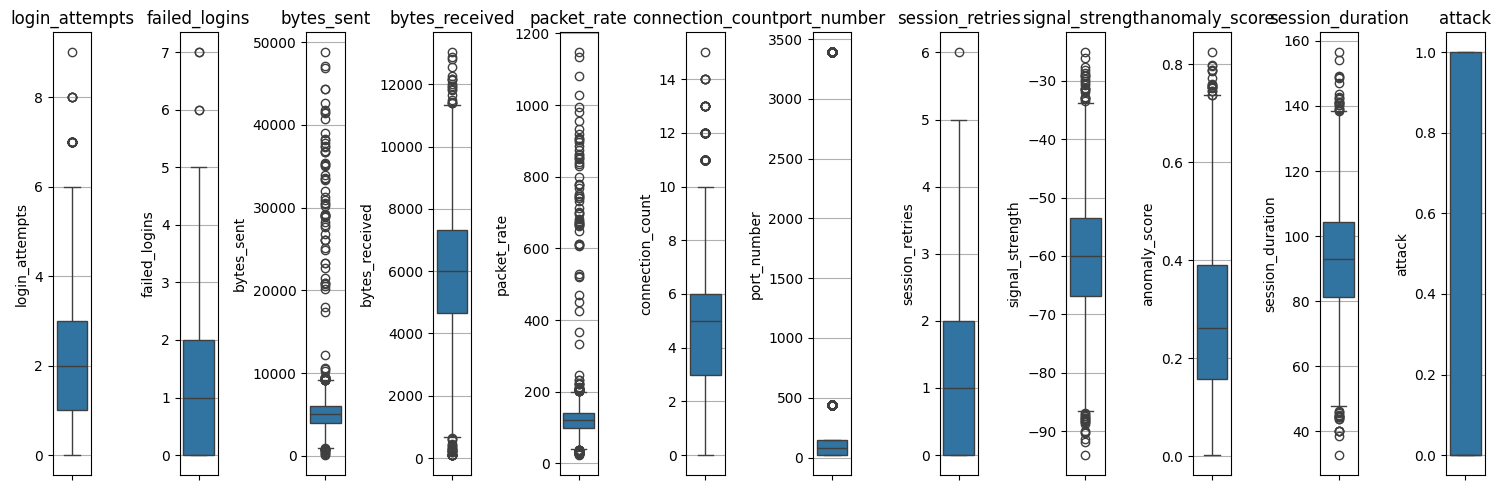

In [15]:
# Outliers Boxplot
num_cols = df.select_dtypes(include='number').columns.tolist()

plt.figure(figsize=(15, 5))
for i, col in enumerate(num_cols, 1):
    plt.subplot(1, len(num_cols), i)
    sns.boxplot(y=df[col])
    plt.title(col)
    plt.grid(axis='y')
plt.tight_layout()
plt.show()

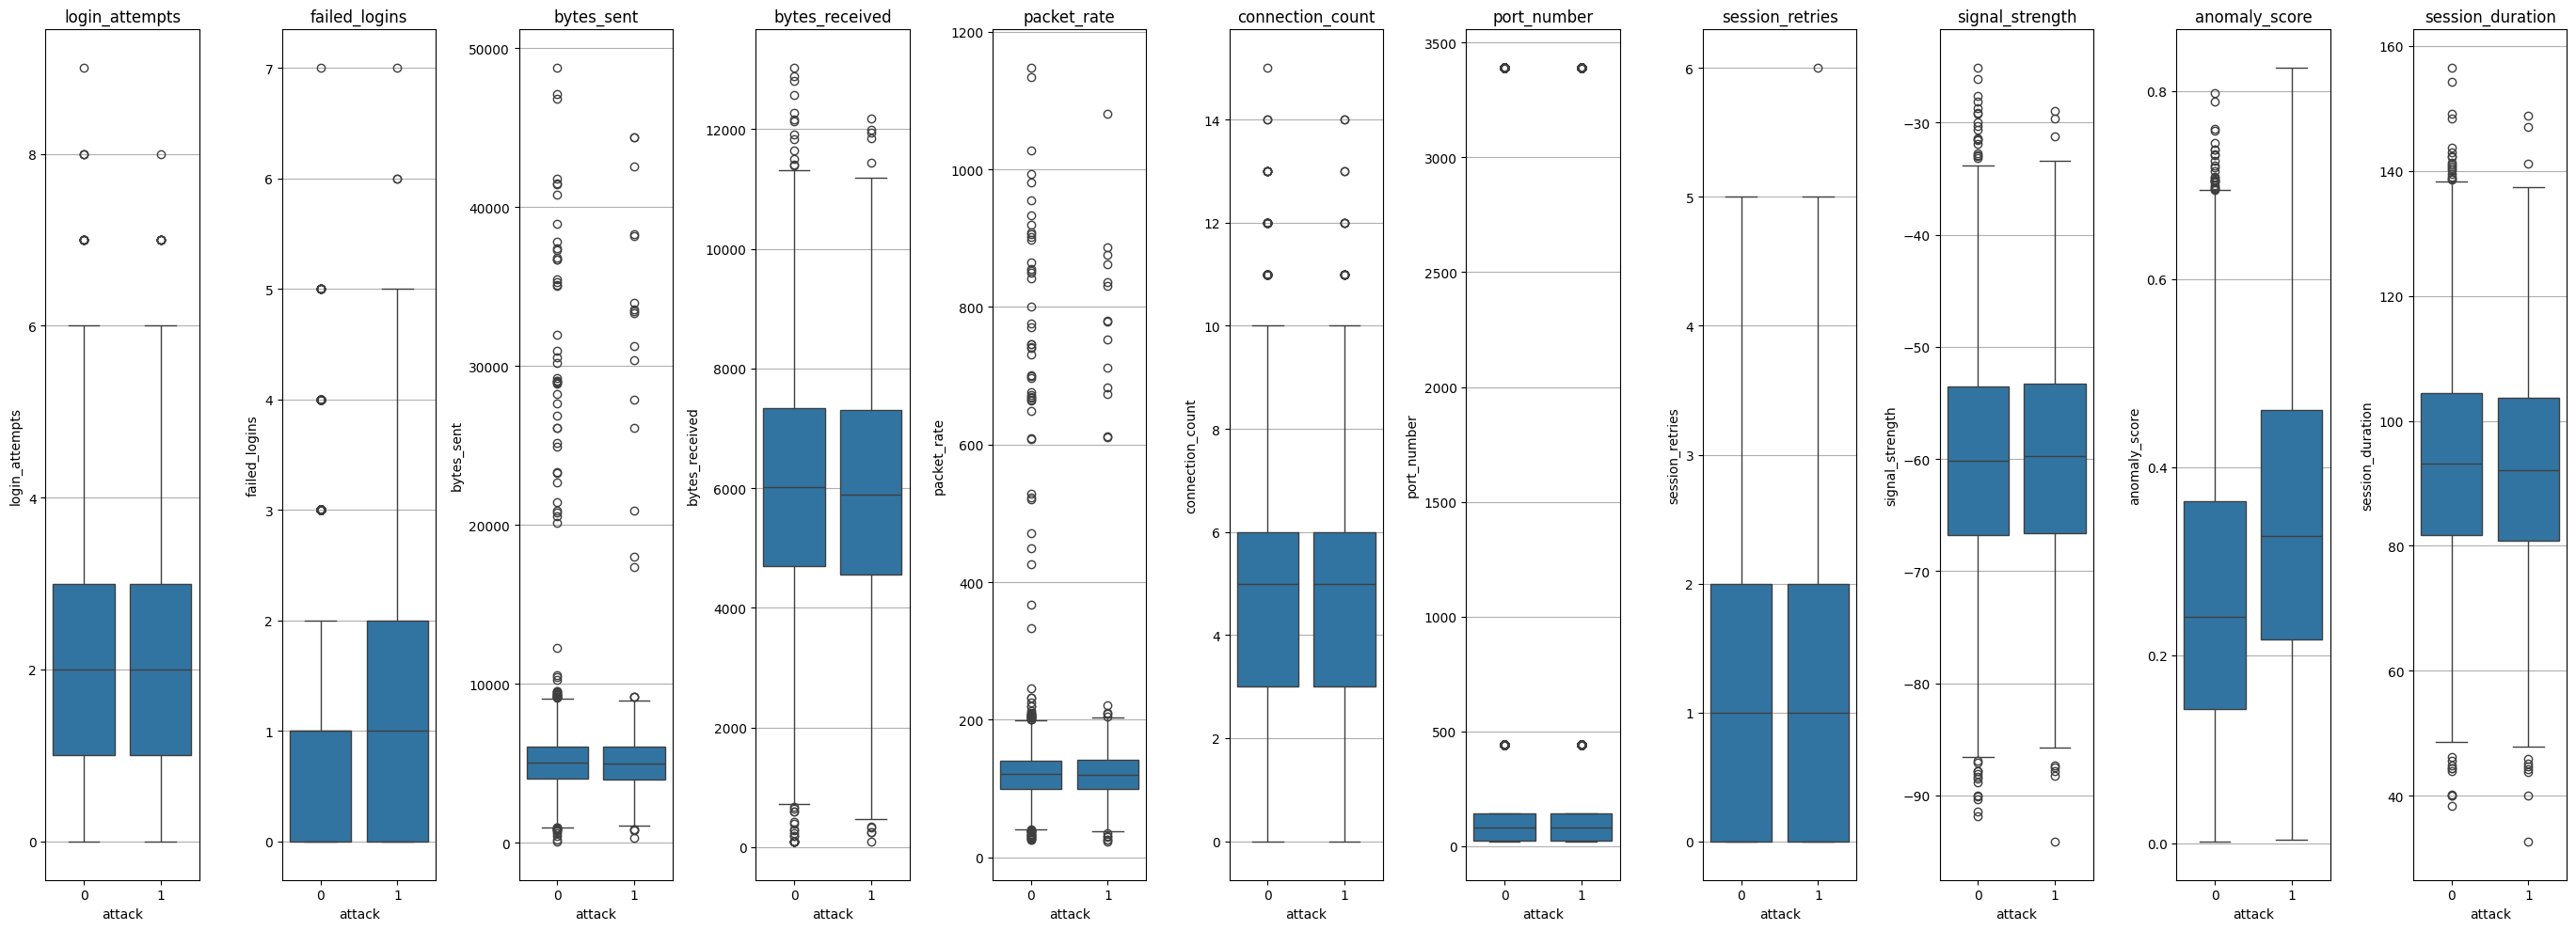

In [16]:
# Numeric Columns vs Target (attack)
num_cols = df.select_dtypes(include='number').columns.tolist()

plt.figure(figsize=(30, 10))
for i, col in enumerate(num_cols, 1):
  if col != 'attack':
    plt.subplot(1, len(num_cols), i)
    sns.boxplot(x='attack', y=col, data=df)
    plt.title(col)
    plt.xlabel('attack')
    plt.grid(axis='y')
plt.tight_layout()
plt.show()

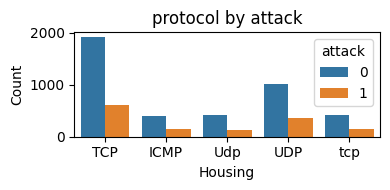

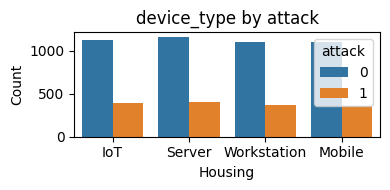

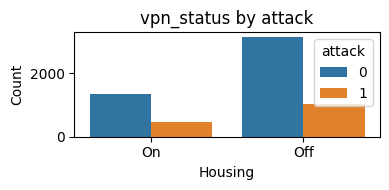

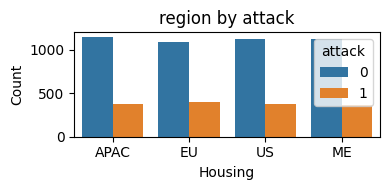

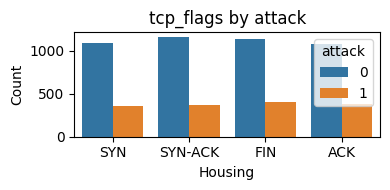

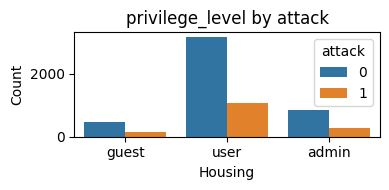

In [17]:
# Categorical Columns vs Target (attack) Version 1
for col in df.select_dtypes(include='object').columns:
    if col not in ['session_id', 'is_attack']:
      plt.figure(figsize=(4, 2))
      sns.countplot(x=col, hue='attack', data=df)
      plt.title(f'{col} by attack')
      plt.xlabel('Housing')
      plt.ylabel('Count')
      plt.tight_layout()
      plt.show()

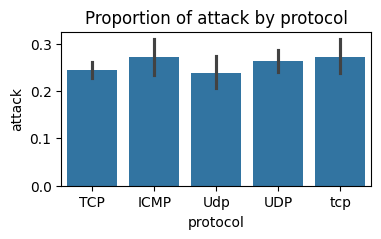

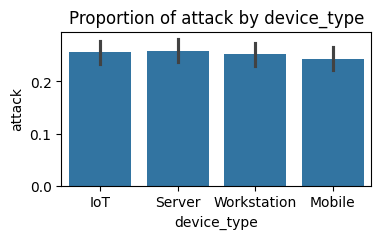

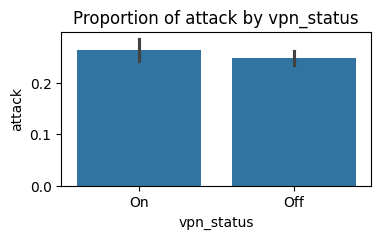

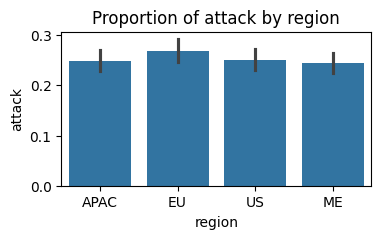

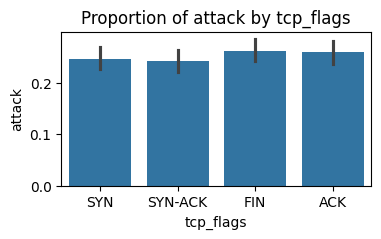

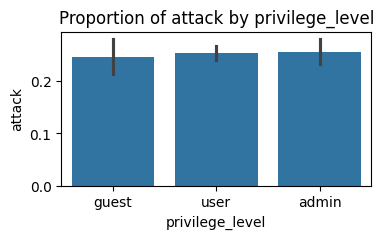

In [18]:
# Categorical Columns vs Target (attack) Version 2
for col in df.select_dtypes(include='object').columns:
    if col not in ['session_id', 'is_attack']:
      plt.figure(figsize=(4, 2))
      sns.barplot(data=df, x=col, y='attack')
      plt.title(f'Proportion of attack by {col}')
      plt.show()

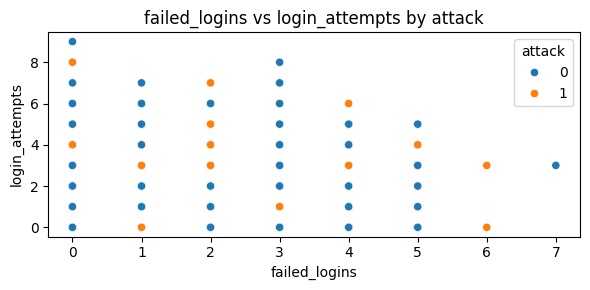

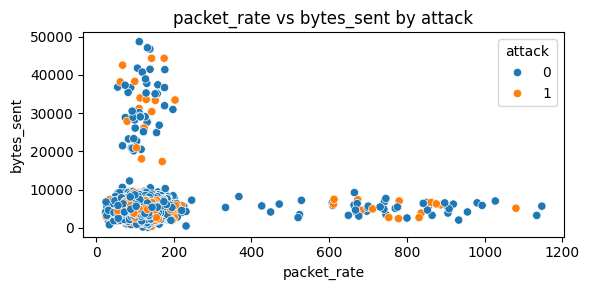

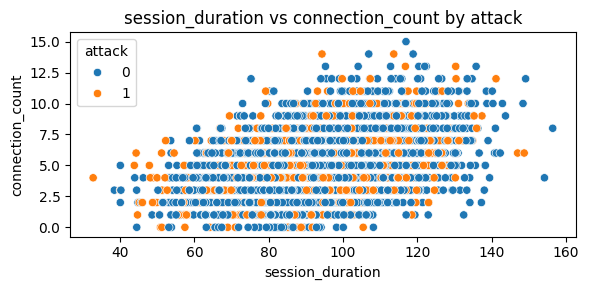

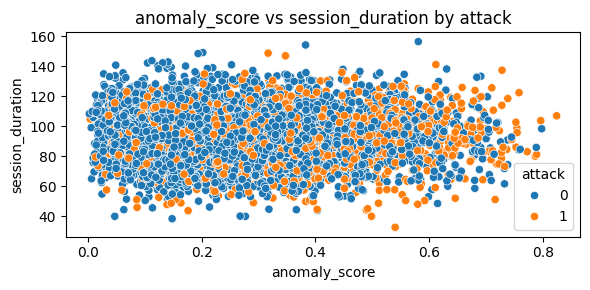

In [19]:
# Scatterplots
# Failed Logins vs Login Attempts
plt.figure(figsize=(6, 3))
sns.scatterplot(x='failed_logins', y='login_attempts', hue='attack', data=df)
plt.title('failed_logins vs login_attempts by attack')
plt.tight_layout()
plt.show()

# Packet Rate vs Bytes Sent
plt.figure(figsize=(6, 3))
sns.scatterplot(x='packet_rate', y='bytes_sent', hue='attack', data=df)
plt.title('packet_rate vs bytes_sent by attack')
plt.tight_layout()
plt.show()

# Session Duration vs Connection Count
plt.figure(figsize=(6, 3))
sns.scatterplot(x='session_duration', y='connection_count', hue='attack', data=df)
plt.title('session_duration vs connection_count by attack')
plt.tight_layout()
plt.show()

# Anomaly Score vs Session Duration
plt.figure(figsize=(6, 3))
sns.scatterplot(x='anomaly_score', y='session_duration', hue='attack', data=df)
plt.title('anomaly_score vs session_duration by attack')
plt.tight_layout()
plt.show()

## Data Preparation

### Creating Baseline Model

In [20]:
# Create Baseline Dataset
df_baseline = df.copy()

# Dropping Useless Columns
df_baseline = df_baseline.drop(['session_id', 'is_attack'], axis=1)

# Numeric Features
num_features = ['failed_logins', 'packet_rate', 'anomaly_score', 'session_duration', 'connection_count', 'signal_strength']
X_baseline = df_baseline[num_features]
y_baseline = df_baseline['attack']

# Remove Missing Values
X_baseline_clean_rows = X_baseline.dropna()
y_baseline_clean_rows = y_baseline[X_baseline_clean_rows.index]

# Encoding
for col in X_baseline_clean_rows.select_dtypes(include='object').columns:
  le_protocol_baseline = LabelEncoder()
  X_baseline_clean_rows[col] = X_baseline_clean_rows[col].astype(str)
  X_baseline_clean_rows[col] = le_protocol_baseline.fit_transform(X_baseline_clean_rows[col])

### Using Decision Tree Classifier on Baseline Model

Baseline Model Decision Tree Classifier
              precision    recall  f1-score   support

           0       0.78      0.97      0.86       848
           1       0.55      0.12      0.20       268

    accuracy                           0.77      1116
   macro avg       0.66      0.54      0.53      1116
weighted avg       0.72      0.77      0.70      1116


Accuracy:  0.7652
Precision: 0.5517
Recall:    0.1194
F1-Score:  0.1963


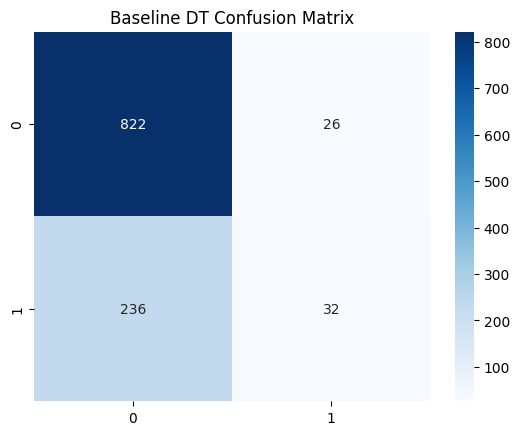


True Negatives:  822
False Positives: 26
False Negatives: 236
True Positives:  32


In [21]:
# Train-Test Split for Baseline
X_train_base, X_test_base, y_train_base, y_test_base = train_test_split(
    X_baseline_clean_rows, y_baseline_clean_rows, test_size=0.2, random_state=42
)

# Decision Tree Classifier
model_base = DecisionTreeClassifier(max_depth=5, random_state=42)
model_base.fit(X_train_base, y_train_base)

# Predictions
y_pred_base = model_base.predict(X_test_base)

# Metrics
acc_base = accuracy_score(y_test_base, y_pred_base)
prec_base = precision_score(y_test_base, y_pred_base)
rec_base = recall_score(y_test_base, y_pred_base)
f1_base = f1_score(y_test_base, y_pred_base)

print("Baseline Model Decision Tree Classifier")
print(classification_report(y_test_base, y_pred_base))
print(f"\nAccuracy:  {acc_base:.4f}")
print(f"Precision: {prec_base:.4f}")
print(f"Recall:    {rec_base:.4f}")
print(f"F1-Score:  {f1_base:.4f}")

# Confusion Matrix
cm_base = confusion_matrix(y_test_base, y_pred_base)
sns.heatmap(cm_base, annot=True, fmt="d", cmap="Blues")
plt.title("Baseline DT Confusion Matrix")
plt.show()
print(f"\nTrue Negatives:  {cm_base[0,0]}")
print(f"False Positives: {cm_base[0,1]}")
print(f"False Negatives: {cm_base[1,0]}")
print(f"True Positives:  {cm_base[1,1]}")

### Creating Improved Model

In [22]:
# Create Cleaned Dataset
df_improved = df.copy()

# Standardise Categorical Columns
for col in df_improved.select_dtypes(include='object').columns:
  df_improved[col] = df_improved[col].str.lower().str.strip()
  print(f"Standardised column: {col}")

# Fix Wrong Values - [no categorical columns found with wrong values]

# Fix Port Values (they are numeric, but shouldn't be (for example, port 433 is higher than port 80, but is ont more important...))
# Convert port_number to string so it is treated as categorical
df_improved['port_number'] = df_improved['port_number'].astype(str)
# Map common ports to names for better readability in feature importance
port_mapping = {
    '80': 'http', '443': 'https', '21': 'ftp', '22': 'ssh',
    '25': 'smtp', '53': 'dns', '110': 'pop3', '143': 'imap', '3389': 'rdp'
}
df_improved['port_number'] = df_improved['port_number'].replace(port_mapping)
print("\nConverted 'port_number' to categorical strings.")

# Handle Missing Values
# Over 40% - [no columns found with >40% missing data]
# 5-40% Missing
df_improved['protocol'] = df_improved['protocol'].fillna(df_improved['protocol'].mode()[0]) # categorical
df_improved['bytes_received'] = df_improved['bytes_received'].fillna(df_improved['bytes_received'].mean()) # symmetric
df_improved['signal_strength'] = df_improved['signal_strength'].fillna(df_improved['signal_strength'].mean()) # symmetric
print("\nImputed column with mode: 'protocol'")
print("Imputed column with mean: 'bytes_received'")
print("Imputed column with mean: 'signal_strength'")
# Impute with median - [no incomplete columns found with skewed data]
# Under 5% Missing - [no columns found with <5% missing data]

# Remove Outliers - [not removing outliers because they may be indicative of an attack (like unusually high packet rates)]

# Remove Columns with only one value - [no columns found with only one unique value]

# Remove Redundant Columns
redundant_cols = ['is_attack']
for col in redundant_cols:
  df_improved = df_improved.drop(col, axis = 1)
  print(f"\nRemoved redundant column: '{col}'")

# Remove Useless Columns
useless_cols = ['session_id']
for col in useless_cols:
  df_improved = df_improved.drop(col, axis = 1)
  print(f"\nRemoved useless column: '{col}'")

# New Features
df_improved['login_failure_rate'] = df_improved['failed_logins'] / (df_improved['login_attempts'] + 1)
print("\nCreated 'login_failure_rate'")
df_improved['data_transfer_ratio'] = df_improved['bytes_sent'] / (df_improved['bytes_received'] + 1)
print("Created 'data_transfer_ratio'")

# Ordinal Encoding 'privilege_level' as it has an order
df_improved[['privilege_level']] = OrdinalEncoder().fit_transform(df_improved[['privilege_level']])
print(f"\nEncoded (Ordinal) column: '{col}'")
# One-Hot Encoding Categorical Features (the categorical columns have no natural order)
cat_cols = df_improved.select_dtypes(include='object').columns.tolist()
df_improved = pd.get_dummies(df_improved, columns=cat_cols, drop_first=True)
print(f"Encoded (One-Hot) columns: {cat_cols}")

# Scale Numeric Features (Min-Max)
print("")
df_prepared = df_improved.copy()
# Split Before Scaling
X_prepared = df_prepared.drop('attack', axis=1)
y_prepared = df_prepared['attack']
X_train, X_test, y_train, y_test = train_test_split(
    X_prepared, y_prepared, test_size=0.2, random_state=42)
# Fit on Training Data & Transform Both
num_cols = X_train.select_dtypes(include='number').columns.tolist()
scaler = MinMaxScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])
print("Fitted Training Data & Transformed Training & Testing Data")

Standardised column: session_id
Standardised column: protocol
Standardised column: device_type
Standardised column: vpn_status
Standardised column: region
Standardised column: tcp_flags
Standardised column: privilege_level
Standardised column: is_attack

Converted 'port_number' to categorical strings.

Imputed column with mode: 'protocol'
Imputed column with mean: 'bytes_received'
Imputed column with mean: 'signal_strength'

Removed redundant column: 'is_attack'

Removed useless column: 'session_id'

Created 'login_failure_rate'
Created 'data_transfer_ratio'

Encoded (Ordinal) column: 'session_id'
Encoded (One-Hot) columns: ['protocol', 'device_type', 'vpn_status', 'region', 'tcp_flags', 'port_number']

Fitted Training Data & Transformed Training & Testing Data


### Using Decision Tree Classifier on Improved Model with GridSearchCV

Improved Model Decision Tree Classifier (GridSearchCV)
Best Params: {'criterion': 'entropy', 'max_depth': 3}
              precision    recall  f1-score   support

           0       0.78      0.98      0.87       933
           1       0.36      0.04      0.08       267

    accuracy                           0.77      1200
   macro avg       0.57      0.51      0.47      1200
weighted avg       0.69      0.77      0.69      1200


Accuracy:  0.7700
Precision: 0.3636
Recall:    0.0449
F1-Score:  0.0800


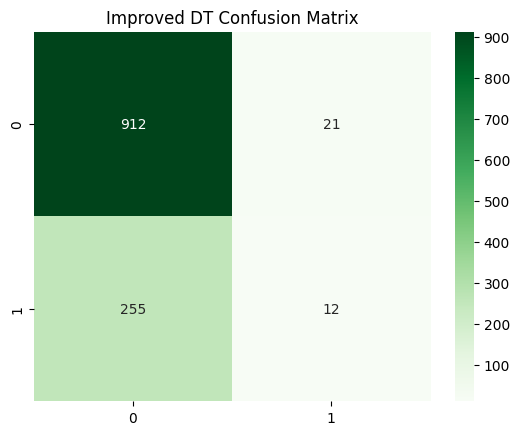


True Negatives:  912
False Positives: 21
False Negatives: 255
True Positives:  12


In [23]:
# Define Parameters
dt_params = {'max_depth': [3, 5, 10, None], 'criterion': ['gini', 'entropy']}
grid_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), dt_params, cv=5)
grid_dt.fit(X_train, y_train)
best_dt = grid_dt.best_estimator_
# Prediction
y_pred_dt = best_dt.predict(X_test)

# Scores
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt)
rec_dt = recall_score(y_test, y_pred_dt)
f1_dt = f1_score(y_test, y_pred_dt)

print("Improved Model Decision Tree Classifier (GridSearchCV)")
print(f"Best Params: {grid_dt.best_params_}")
print(classification_report(y_test, y_pred_dt))
print(f"\nAccuracy:  {acc_dt:.4f}")
print(f"Precision: {prec_dt:.4f}")
print(f"Recall:    {rec_dt:.4f}")
print(f"F1-Score:  {f1_dt:.4f}")

# Confusion Matrix
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt="d", cmap="Greens")
plt.title("Improved DT Confusion Matrix")
plt.show()
print(f"\nTrue Negatives:  {cm_dt[0,0]}")
print(f"False Positives: {cm_dt[0,1]}")
print(f"False Negatives: {cm_dt[1,0]}")
print(f"True Positives:  {cm_dt[1,1]}")

### Using KNN Classifier on Improved Model with GridSearchCV

Improved Model KNN Classifier (GridSearchCV)
Best Params: {'n_neighbors': 9, 'weights': 'uniform'}
              precision    recall  f1-score   support

           0       0.78      0.95      0.85       933
           1       0.23      0.06      0.09       267

    accuracy                           0.75      1200
   macro avg       0.51      0.50      0.47      1200
weighted avg       0.66      0.75      0.68      1200


Accuracy:  0.7492
Precision: 0.2344
Recall:    0.0562
F1-Score:  0.0906


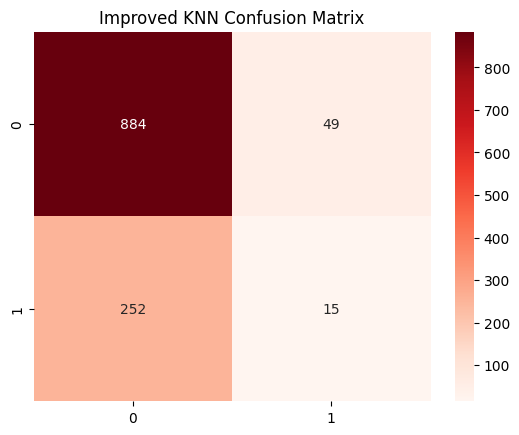


True Negatives:  884
False Positives: 49
False Negatives: 252
True Positives:  15


In [24]:
# Define Parameters
knn_params = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
grid_knn = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5)
grid_knn.fit(X_train, y_train)
best_knn = grid_knn.best_estimator_
# Prediction
y_pred_knn = best_knn.predict(X_test)

# Scores
acc_knn = accuracy_score(y_test, y_pred_knn)
prec_knn = precision_score(y_test, y_pred_knn)
rec_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)

print("Improved Model KNN Classifier (GridSearchCV)")
print(f"Best Params: {grid_knn.best_params_}")
print(classification_report(y_test, y_pred_knn))
print(f"\nAccuracy:  {acc_knn:.4f}")
print(f"Precision: {prec_knn:.4f}")
print(f"Recall:    {rec_knn:.4f}")
print(f"F1-Score:  {f1_knn:.4f}")

# Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Reds")
plt.title("Improved KNN Confusion Matrix")
plt.show()
print(f"\nTrue Negatives:  {cm_knn[0,0]}")
print(f"False Positives: {cm_knn[0,1]}")
print(f"False Negatives: {cm_knn[1,0]}")
print(f"True Positives:  {cm_knn[1,1]}")

### Using Linear Regression on Improved Model with GridSearchCV

Improved Model Linear Regression (Session Duration)
MAE: 0.0800
RMSE: 0.1008
R2 Score: 0.4599


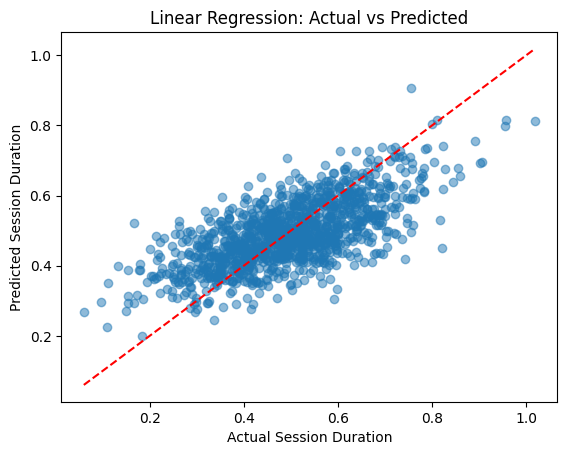

In [25]:
# Preparing data ('session_duration' is the target and not in features)
X_reg_train = X_train.drop(columns=['session_duration'])
X_reg_test = X_test.drop(columns=['session_duration'])
y_reg_train = X_train['session_duration']
y_reg_test = X_test['session_duration']

grid_lr = GridSearchCV(LinearRegression(), {'fit_intercept': [True, False]}, cv=5)
grid_lr.fit(X_reg_train, y_reg_train)
y_pred_lr = grid_lr.predict(X_reg_test)

print("Improved Model Linear Regression (Session Duration)")
print(f"MAE: {mean_absolute_error(y_reg_test, y_pred_lr):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_reg_test, y_pred_lr)):.4f}")
print(f"R2 Score: {r2_score(y_reg_test, y_pred_lr):.4f}")

# Regression visualization: Actual vs Predicted
plt.scatter(y_reg_test, y_pred_lr, alpha=0.5)
plt.plot([y_reg_test.min(), y_reg_test.max()], [y_reg_test.min(), y_reg_test.max()], 'r--')
plt.xlabel("Actual Session Duration")
plt.ylabel("Predicted Session Duration")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

## Data Comparison (for Classifiers)

In [26]:
# Note: Regression is excluded from the classification table as metrics differ
comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Baseline (DT)': [acc_base, prec_base, rec_base, f1_base],
    'Improved (DT)': [acc_dt, prec_dt, rec_dt, f1_dt],
    'Improved (KNN)': [acc_knn, prec_knn, rec_knn, f1_knn]
}
comparison_df = pd.DataFrame(comparison_data)

comparison_df['Improved DT vs Baseline DT (%)'] = ((comparison_df['Improved (DT)'] - comparison_df['Baseline (DT)']) / comparison_df['Baseline (DT)']) * 100
comparison_df['Improved KNN vs Baseline DT (%)'] = ((comparison_df['Improved (KNN)'] - comparison_df['Baseline (DT)']) / comparison_df['Baseline (DT)']) * 100
comparison_df['Improved DT vs Improved KNN (%)'] = ((comparison_df['Improved (DT)'] - comparison_df['Improved (KNN)']) / comparison_df['Improved (KNN)']) * 100
print("Comparing Classifiers")
print(comparison_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nKey Performance Insights")
print(f"- Improved DT vs Baseline DT:  {((acc_dt - acc_base) * 100):+.2f}% accuracy change")
print(f"- Improved KNN vs Baseline DT: {((acc_knn - acc_base) * 100):+.2f}% accuracy change")
print(f"- Improved DT vs Improved KNN: {((acc_dt - acc_knn) * 100):+.2f}% accuracy difference")

print("\nExcluding the Baseline")
best_model = "Decision Tree" if acc_dt > acc_knn else "KNN"
print(f"- The Improved {best_model} has the best Accuracy.")
best_model = "Decision Tree" if prec_dt > prec_knn else "KNN"
print(f"- The Improved {best_model} has the best Precision.")
best_model = "Decision Tree" if rec_dt > rec_knn else "KNN"
print(f"- The Improved {best_model} has the best Recall.")
best_model = "Decision Tree" if f1_dt > f1_knn else "KNN"
print(f"- The Improved {best_model} is the best F1-Score.")

Comparing Classifiers
   Metric  Baseline (DT)  Improved (DT)  Improved (KNN)  Improved DT vs Baseline DT (%)  Improved KNN vs Baseline DT (%)  Improved DT vs Improved KNN (%)
 Accuracy         0.7652         0.7700          0.7492                          0.6230                          -2.0995                           2.7809
Precision         0.5517         0.3636          0.2344                        -34.0909                         -57.5195                          55.1515
   Recall         0.1194         0.0449          0.0562                        -62.3596                         -52.9494                         -20.0000
 F1-Score         0.1963         0.0800          0.0906                        -59.2500                         -53.8331                         -11.7333

Key Performance Insights
- Improved DT vs Baseline DT:  +0.48% accuracy change
- Improved KNN vs Baseline DT: -1.61% accuracy change
- Improved DT vs Improved KNN: +2.08% accuracy difference

Excluding the B

### Extra Comparison: Improved + Outliers vs Improved - Outliers

In [27]:
# Create Cleaned Dataset
df_no_outliers = df.copy()

# Standardise Categorical Columns
for col in df_no_outliers.select_dtypes(include='object').columns:
  df_no_outliers[col] = df_no_outliers[col].str.lower().str.strip()

# Fix Wrong Values - [no categorical columns found with wrong values]

# Fix Port Values (they are numeric, but shouldn't be (for example, port 433 is higher than port 80, but is ont more important...))
# Convert port_number to string so it is treated as categorical
df_no_outliers['port_number'] = df_no_outliers['port_number'].astype(str)
# Map common ports to names for better readability in feature importance
port_mapping = {
    '80': 'HTTP', '443': 'HTTPS', '21': 'FTP', '22': 'SSH',
    '25': 'SMTP', '53': 'DNS', '110': 'POP3', '143': 'IMAP', '3389': 'RDP'
}
df_no_outliers['port_number'] = df_no_outliers['port_number'].replace(port_mapping)

# Handle Missing Values
# Over 40% - [no columns found with >40% missing data]
# 5-40% Missing
df_no_outliers['protocol'] = df_no_outliers['protocol'].fillna(df_no_outliers['protocol'].mode()[0]) # categorical
df_no_outliers['bytes_received'] = df_no_outliers['bytes_received'].fillna(df_no_outliers['bytes_received'].mean()) # symmetric
df_no_outliers['signal_strength'] = df_no_outliers['signal_strength'].fillna(df_no_outliers['signal_strength'].mean()) # symmetric
# Impute with median - [no incomplete columns found with skewed data]
# Under 5% Missing - [no columns found with <5% missing data]
df_no_outliers.dropna(inplace=True)
df_no_outliers.reset_index(drop=True, inplace=True)

# Remove Outliers - [USED]
def remove_outliers_iqr(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower = Q1 - 1.5 * IQR
  upper = Q3 + 1.5 * IQR
  before = len(df)
  df_clean = df[(df[column] >= lower) & (df[column] <= upper)]
  after = len(df_clean)
  print(f"{column}: removed {before - after} rows | bounds [{lower:.2f}, {upper:.2f}]")
  return df_clean
# Apply to all numeric columns
numeric_cols = df_no_outliers.select_dtypes(include='number').columns
for col in numeric_cols:
 df_no_outliers = remove_outliers_iqr(df_no_outliers, col)
df_no_outliers.reset_index(drop=True, inplace=True)

# Remove Columns with only one value - [no columns found with only one unique value]

# Remove Redundant Columns
redundant_cols = ['is_attack']
for col in redundant_cols:
  df_no_outliers = df_no_outliers.drop(col, axis = 1)

# Remove Useless Columns
useless_cols = ['session_id']
for col in useless_cols:
  df_no_outliers = df_no_outliers.drop(col, axis = 1)

# New Features
df_no_outliers['login_failure_rate'] = df_no_outliers['failed_logins'] / (df_no_outliers['login_attempts'] + 1)
df_no_outliers['data_transfer_ratio'] = df_no_outliers['bytes_sent'] / (df_no_outliers['bytes_received'] + 1)

# Ordinal Encoding 'privilege_level' as it has an order
df_no_outliers[['privilege_level']] = OrdinalEncoder().fit_transform(df_no_outliers[['privilege_level']])
# One-Hot Encoding Categorical Features (the categorical columns have no natural order)
cat_cols = df_no_outliers.select_dtypes(include='object').columns.tolist()
df_no_outliers = pd.get_dummies(df_no_outliers, columns=cat_cols, drop_first=True)

# Scale Numeric Features (Min-Max)
print("")
df_prepared_out = df_no_outliers.copy()
# Split Before Scaling
X_prepared_out = df_prepared_out.drop('attack', axis=1)
y_prepared_out = df_prepared_out['attack']
X_train_out, X_test_out, y_train_out, y_test_out = train_test_split(
    X_prepared_out, y_prepared_out, test_size=0.2, random_state=42)
# Fit on Training Data & Transform Both
num_cols = X_train_out.select_dtypes(include='number').columns.tolist()
scaler = MinMaxScaler()
X_train_out[num_cols] = scaler.fit_transform(X_train_out[num_cols])
X_test_out[num_cols] = scaler.transform(X_test_out[num_cols])

login_attempts: removed 27 rows | bounds [-2.00, 6.00]
failed_logins: removed 4 rows | bounds [-3.00, 5.00]
bytes_sent: removed 94 rows | bounds [942.73, 9136.25]
bytes_received: removed 84 rows | bounds [1084.02, 10892.79]
packet_rate: removed 105 rows | bounds [39.69, 200.87]
connection_count: removed 93 rows | bounds [-1.50, 10.50]
session_retries: removed 1 rows | bounds [-3.00, 5.00]
signal_strength: removed 70 rows | bounds [-84.47, -35.41]
anomaly_score: removed 17 rows | bounds [-0.19, 0.73]
session_duration: removed 32 rows | bounds [47.80, 137.18]
attack: removed 0 rows | bounds [-1.50, 2.50]



#### Decision Trees Comparison



In [28]:
# Define Parameters
out_dt_params = {'max_depth': [3, 5, 10, None], 'criterion': ['gini', 'entropy']}
grid_out_dt = GridSearchCV(DecisionTreeClassifier(random_state=42), out_dt_params, cv=5)
grid_out_dt.fit(X_train_out, y_train_out)
best_out_dt = grid_out_dt.best_estimator_
y_pred_out_dt = best_out_dt.predict(X_test_out)

acc_out_dt = accuracy_score(y_test_out, y_pred_out_dt)
prec_out_dt = precision_score(y_test_out, y_pred_out_dt)
rec_out_dt = recall_score(y_test_out, y_pred_out_dt)
f1_out_dt = f1_score(y_test_out, y_pred_out_dt)

In [29]:
# Decision Tree with Outliers vs without Outliers
comparison_data_2 = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Improved (DT + Outliers)': [acc_dt, prec_dt, rec_dt, f1_dt],
    'Improved (DT - Outliers)': [acc_out_dt, prec_out_dt, rec_out_dt, f1_out_dt]
}
comparison_df_2 = pd.DataFrame(comparison_data_2)

comparison_df_2['Improved (DT + Outliers) vs Improved (DT - Outliers)'] = ((comparison_df_2['Improved (DT + Outliers)'] - comparison_df_2['Improved (DT - Outliers)']) / comparison_df_2['Improved (DT - Outliers)']) * 100
print("Comparing Classifiers")
print(comparison_df_2.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nKey Performance Insights")
print(f"- Improved (DT + Outliers) vs Improved (DT - Outliers):  {((acc_dt - acc_out_dt) * 100):+.2f}% accuracy change")
best_model = "(+ Outliers)" if acc_dt > acc_out_dt else "(- Outliers)"
print(f"- The Improved DT {best_model} has the best Accuracy.")
best_model = "(+ Outliers)" if prec_dt > prec_out_dt else "(- Outliers)"
print(f"- The Improved DT {best_model} has the best Precision.")
best_model = "(+ Outliers)" if rec_dt > rec_out_dt else "(- Outliers)"
print(f"- The Improved DT {best_model} has the best Recall.")
best_model = "(+ Outliers)" if f1_dt > f1_out_dt else "(- Outliers)"
print(f"- The Improved DT {best_model} is the best F1-Score.")

Comparing Classifiers
   Metric  Improved (DT + Outliers)  Improved (DT - Outliers)  Improved (DT + Outliers) vs Improved (DT - Outliers)
 Accuracy                    0.7700                    0.7397                                                4.0926
Precision                    0.3636                    0.5417                                              -32.8671
   Recall                    0.0449                    0.0453                                               -0.7779
 F1-Score                    0.0800                    0.0836                                               -4.3077

Key Performance Insights
- Improved (DT + Outliers) vs Improved (DT - Outliers):  +3.03% accuracy change
- The Improved DT (+ Outliers) has the best Accuracy.
- The Improved DT (- Outliers) has the best Precision.
- The Improved DT (- Outliers) has the best Recall.
- The Improved DT (- Outliers) is the best F1-Score.


#### KNNs Comparison

In [30]:
# Define Parameters
out_knn_params = {'n_neighbors': [3, 5, 7, 9], 'weights': ['uniform', 'distance']}
grid_out_knn = GridSearchCV(KNeighborsClassifier(), out_knn_params, cv=5)
grid_out_knn.fit(X_train_out, y_train_out)
best_out_knn = grid_out_knn.best_estimator_
y_pred_out_knn = best_out_knn.predict(X_test_out)

acc_out_knn = accuracy_score(y_test_out, y_pred_out_knn)
prec_out_knn = precision_score(y_test_out, y_pred_out_knn)
rec_out_knn = recall_score(y_test_out, y_pred_out_knn)
f1_out_knn = f1_score(y_test_out, y_pred_out_knn)

In [31]:
# KNN Outliers vs without Outliers
comparison_data_3 = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Improved (KNN + Outliers)': [acc_knn, prec_knn, rec_knn, f1_knn],
    'Improved (KNN - Outliers)': [acc_out_knn, prec_out_knn, rec_out_knn, f1_out_knn]
}
comparison_df_3 = pd.DataFrame(comparison_data_3)

comparison_df_3['Improved (KNN + Outliers) vs Improved (KNN - Outliers)'] = ((comparison_df_3['Improved (KNN + Outliers)'] - comparison_df_3['Improved (KNN - Outliers)']) / comparison_df_3['Improved (KNN - Outliers)']) * 100
print("Comparing Classifiers")
print(comparison_df_3.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nKey Performance Insights")
print(f"- Improved (KNN + Outliers) vs Improved (KNN - Outliers):  {((acc_knn - acc_out_knn) * 100):+.2f}% accuracy change")
best_model = "(+ Outliers)" if acc_knn > acc_out_knn else "(- Outliers)"
print(f"- The Improved KNN {best_model} has the best Accuracy.")
best_model = "(+ Outliers)" if prec_knn > prec_out_knn else "(- Outliers)"
print(f"- The Improved KNN {best_model} has the best Precision.")
best_model = "(+ Outliers)" if rec_knn > rec_out_knn else "(- Outliers)"
print(f"- The Improved KNN {best_model} has the best Recall.")
best_model = "(+ Outliers)" if f1_knn > f1_out_knn else "(- Outliers)"
print(f"- The Improved KNN {best_model} is the best F1-Score.")

Comparing Classifiers
   Metric  Improved (KNN + Outliers)  Improved (KNN - Outliers)  Improved (KNN + Outliers) vs Improved (KNN - Outliers)
 Accuracy                     0.7492                     0.7087                                                  5.7136
Precision                     0.2344                     0.1667                                                 40.6250
   Recall                     0.0562                     0.0279                                                101.5449
 F1-Score                     0.0906                     0.0478                                                 89.7659

Key Performance Insights
- Improved (KNN + Outliers) vs Improved (KNN - Outliers):  +4.05% accuracy change
- The Improved KNN (+ Outliers) has the best Accuracy.
- The Improved KNN (+ Outliers) has the best Precision.
- The Improved KNN (+ Outliers) has the best Recall.
- The Improved KNN (+ Outliers) is the best F1-Score.


#### DT (- Outliers) vs KNN (- Outliers)

In [32]:
# Decision Tree No Outliers vs KNN No Outliers
comparison_data_4 = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Improved (DT - Outliers)': [acc_out_dt, prec_out_dt, rec_out_dt, f1_out_dt],
    'Improved (KNN - Outliers)': [acc_out_knn, prec_out_knn, rec_out_knn, f1_out_knn]
}
comparison_df_4 = pd.DataFrame(comparison_data_4)

comparison_df_4['Improved (DT - Outliers) vs Improved (KNN - Outliers)'] = ((comparison_df_4['Improved (DT - Outliers)'] - comparison_df_4['Improved (KNN - Outliers)']) / comparison_df_4['Improved (KNN - Outliers)']) * 100
print("Comparing Classifiers")
print(comparison_df_4.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

print("\nKey Performance Insights")
print(f"- Improved (DT - Outliers) vs Improved (KNN - Outliers):  {((acc_out_dt - acc_out_knn) * 100):+.2f}% accuracy change")
best_model = "Decision Tree" if acc_out_dt > acc_out_knn else "KNN"
print(f"- The Improved {best_model} (- Outliers) has the best Accuracy.")
best_model = "Decision Tree" if prec_out_dt > prec_out_knn else "KNN"
print(f"- The Improved {best_model} (- Outliers) has the best Precision.")
best_model = "Decision Tree" if rec_out_dt > rec_out_knn else "KNN"
print(f"- The Improved {best_model} (- Outliers) has the best Recall.")
best_model = "Decision Tree" if f1_out_dt > f1_out_knn else "KNN"
print(f"- The Improved {best_model} (- Outliers) is the best F1-Score.")

Comparing Classifiers
   Metric  Improved (DT - Outliers)  Improved (KNN - Outliers)  Improved (DT - Outliers) vs Improved (KNN - Outliers)
 Accuracy                    0.7397                     0.7087                                                 4.3814
Precision                    0.5417                     0.1667                                               225.0000
   Recall                    0.0453                     0.0279                                                62.5000
 F1-Score                    0.0836                     0.0478                                                75.0402

Key Performance Insights
- Improved (DT - Outliers) vs Improved (KNN - Outliers):  +3.11% accuracy change
- The Improved Decision Tree (- Outliers) has the best Accuracy.
- The Improved Decision Tree (- Outliers) has the best Precision.
- The Improved Decision Tree (- Outliers) has the best Recall.
- The Improved Decision Tree (- Outliers) is the best F1-Score.


### Extra Comparison: Noisy Baseline

In [33]:
# Create Baseline Dataset
df_baseline_worse = df.copy()

# Dropping Useless Columns
df_baseline_worse = df_baseline_worse.drop(['session_id', 'is_attack'], axis=1)

# Numeric Features
num_cols = df_baseline_worse.select_dtypes(include='object').columns.tolist()
X_baseline_worse = df_baseline_worse[num_cols]
y_baseline_worse = df_baseline_worse['attack']

# Remove Missing Values
X_baseline_worse_clean_rows = X_baseline_worse.dropna()
y_baseline_worse_clean_rows = y_baseline_worse[X_baseline_worse_clean_rows.index]

# Encoding
for col in X_baseline_worse_clean_rows.select_dtypes(include='object').columns:
  le_protocol_baseline_worse = LabelEncoder()
  X_baseline_worse_clean_rows[col] = X_baseline_worse_clean_rows[col].astype(str)
  X_baseline_worse_clean_rows[col] = le_protocol_baseline_worse.fit_transform(X_baseline_worse_clean_rows[col])

Baseline Model Decision Tree Classifier
              precision    recall  f1-score   support

           0       0.75      1.00      0.85       832
           1       0.00      0.00      0.00       284

    accuracy                           0.75      1116
   macro avg       0.37      0.50      0.43      1116
weighted avg       0.56      0.75      0.64      1116


Accuracy:  0.7455
Precision: 0.0000
Recall:    0.0000
F1-Score:  0.0000


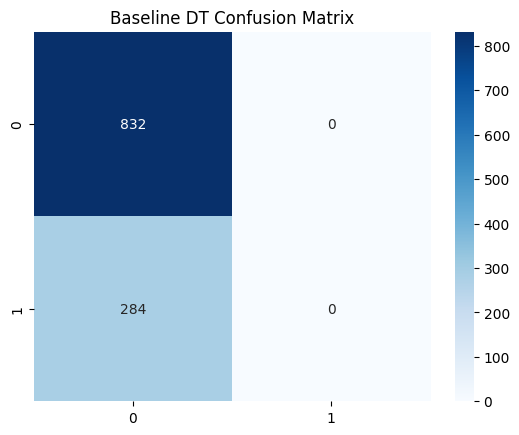


True Negatives:  832
False Positives: 0
False Negatives: 284
True Positives:  0


In [34]:
# Train-Test Split for Baseline
X_train_base_worse, X_test_base_worse, y_train_base_worse, y_test_base_worse = train_test_split(
    X_baseline_worse_clean_rows, y_baseline_worse_clean_rows, test_size=0.2, random_state=42
)

# Decision Tree Classifier
model_base_worse = DecisionTreeClassifier(max_depth=5, random_state=42)
model_base_worse.fit(X_train_base_worse, y_train_base_worse)

# Predictions
y_pred_base_worse = model_base_worse.predict(X_test_base_worse)

# Metrics
acc_base_worse = accuracy_score(y_test_base_worse, y_pred_base_worse)
prec_base_worse = precision_score(y_test_base_worse, y_pred_base_worse)
rec_base_worse = recall_score(y_test_base_worse, y_pred_base_worse)
f1_base_worse = f1_score(y_test_base_worse, y_pred_base_worse)

print("Baseline Model Decision Tree Classifier")
print(classification_report(y_test_base_worse, y_pred_base_worse))
print(f"\nAccuracy:  {acc_base_worse:.4f}")
print(f"Precision: {prec_base_worse:.4f}")
print(f"Recall:    {rec_base_worse:.4f}")
print(f"F1-Score:  {f1_base_worse:.4f}")

# Confusion Matrix
cm_base_worse = confusion_matrix(y_test_base_worse, y_pred_base_worse)
sns.heatmap(cm_base_worse, annot=True, fmt="d", cmap="Blues")
plt.title("Baseline DT Confusion Matrix")
plt.show()
print(f"\nTrue Negatives:  {cm_base_worse[0,0]}")
print(f"False Positives: {cm_base_worse[0,1]}")
print(f"False Negatives: {cm_base_worse[1,0]}")
print(f"True Positives:  {cm_base_worse[1,1]}")